# Proyek Analisis Data: Air Quality Dataset (PRSA Beijing Multi-Site)
- **Nama:** Moh. Syahril A. Kadili
- **Email:** arilkadili21@gmail.com
- **ID Dicoding:** DS323B6Y1016

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

Dataset yang digunakan adalah **Air Quality Dataset (PRSA)**: data kualitas udara per jam dari **12 stasiun pemantauan di Beijing**, periode **1 Maret 2013 – 28 Februari 2017**, berisi polutan (PM2.5, PM10, SO2, NO2, CO, O3) dan variabel cuaca (suhu, tekanan, titik embun, hujan, arah dan kecepatan angin).

- **Pertanyaan 1:** Stasiun pemantauan mana (dari 12 stasiun) yang memiliki rata-rata konsentrasi PM2.5 tertinggi dan terendah selama Maret 2013 – Februari 2017, dan berapa persen selisih keduanya, sehingga pengelola dapat memprioritaskan wilayah untuk pengendalian polusi?
- **Pertanyaan 2:** Pada bulan apa rata-rata PM2.5 bulanan tertinggi dan terendah sepanjang tiga tahun penuh (2014–2016), dan berapa kali lipat selisihnya, sehingga dapat ditentukan periode pengetatan pengendalian emisi dan imbauan kesehatan?

**Penjelasan SMART:**

| Unsur | Pertanyaan 1 | Pertanyaan 2 |
|---|---|---|
| Specific | Fokus pada PM2.5 dan perbandingan antar 12 stasiun | Fokus pada pola bulanan PM2.5 (musiman) |
| Measurable | Rata-rata PM2.5 (µg/m³) dan selisih persentase | Rata-rata PM2.5 bulanan (µg/m³) dan rasio bulan tertinggi vs terendah |
| Action-Oriented | Menentukan stasiun/wilayah prioritas intervensi | Menentukan periode pengetatan emisi dan imbauan masker |
| Relevant | PM2.5 adalah polutan paling berbahaya bagi kesehatan | Pola musiman menentukan kapan intervensi paling efektif |
| Time-bound | Mar 2013 – Feb 2017 | 2014 – 2016 (hanya tahun yang datanya lengkap 12 bulan) |

## Import Semua Packages/Library yang Digunakan

In [4]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
%matplotlib inline

## Data Wrangling

### Gathering Data

#### Load seluruh file CSV stasiun menjadi satu DataFrame

In [5]:
# Setiap stasiun disimpan dalam satu file CSV pada folder data/
files = sorted(glob.glob('data/*.csv'))
print('Jumlah file:', len(files))

df_raw = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
print('Ukuran data (baris, kolom):', df_raw.shape)
display(df_raw.head())
display(df_raw['station'].value_counts().sort_index())

Jumlah file: 12
Ukuran data (baris, kolom): (420768, 18)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


station
Aotizhongxin     35064
Changping        35064
Dingling         35064
Dongsi           35064
Guanyuan         35064
Gucheng          35064
Huairou          35064
Nongzhanguan     35064
Shunyi           35064
Tiantan          35064
Wanliu           35064
Wanshouxigong    35064
Name: count, dtype: int64

**Insight:**
- Terdapat **12 file CSV** (satu per stasiun) yang digabung menjadi **420.768 baris x 18 kolom**.
- Setiap stasiun memiliki jumlah baris yang sama (**35.064 baris**, data per jam selama 4 tahun), sehingga perbandingan antar stasiun adil.
- Waktu tersimpan terpisah dalam kolom `year`, `month`, `day`, `hour` dan perlu digabung menjadi satu kolom datetime.

### Assessing Data

#### Identifying missing value, duplicate data, invalid value, dan outlier

In [6]:
df_raw.info()

# 1) Missing value
print('\n=== Missing value per kolom ===')
missing = df_raw.isna().sum()
display(pd.DataFrame({'jumlah': missing, 'persen': (missing / len(df_raw) * 100).round(2)})[missing > 0])

# 2) Duplicate data
print('Jumlah data duplikat (seluruh kolom):', df_raw.duplicated().sum())
print('Duplikat kombinasi waktu + stasiun:', df_raw.duplicated(subset=['year','month','day','hour','station']).sum())

# 3) Invalid value: PM2.5 adalah bagian dari PM10, sehingga PM10 tidak boleh lebih kecil dari PM2.5
both = df_raw.dropna(subset=['PM2.5', 'PM10'])
invalid = (both['PM10'] < both['PM2.5'])
print(f'\nBaris dengan PM10 < PM2.5: {invalid.sum()} ({invalid.mean()*100:.1f}% dari baris yang lengkap)')

# 4) Outlier PM2.5 dengan metode IQR
q1, q3 = df_raw['PM2.5'].quantile([0.25, 0.75])
batas_atas = q3 + 1.5 * (q3 - q1)
n_out = (df_raw['PM2.5'] > batas_atas).sum()
print(f'Outlier PM2.5 (> {batas_atas:.1f} µg/m³): {n_out} baris ({n_out/len(df_raw)*100:.1f}%)')

# 5) Ringkasan statistik dan nilai kategorikal arah angin
display(df_raw.describe().T)
print(df_raw['wd'].unique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  object 
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 57.8+ MB

=== Missing value per kolom ===


,jumlah,persen
PM2.5,8739,2.08
PM10,6449,1.53
SO2,9021,2.14
NO2,12116,2.88
CO,20701,4.92
O3,13277,3.16
TEMP,398,0.09
PRES,393,0.09
DEWP,403,0.10
RAIN,390,0.09


Jumlah data duplikat (seluruh kolom): 0
Duplikat kombinasi waktu + stasiun: 0

Baris dengan PM10 < PM2.5: 21312 (5.2% dari baris yang lengkap)
Outlier PM2.5 (> 247.5 µg/m³): 19142 baris (4.5%)


,count,mean,std,min,25%,50%,75%,max
No,420768.0,17532.500000,10122.116943,1.0000,8766.75,17532.5,26298.25,35064.0
year,420768.0,2014.662560,1.177198,2013.0000,2014.00,2015.0,2016.00,2017.0
month,420768.0,6.522930,3.448707,1.0000,4.00,7.0,10.00,12.0
day,420768.0,15.729637,8.800102,1.0000,8.00,16.0,23.00,31.0
hour,420768.0,11.500000,6.922195,0.0000,5.75,11.5,17.25,23.0
PM2.5,412029.0,79.793428,80.822391,2.0000,20.00,55.0,111.00,999.0
PM10,414319.0,104.602618,91.772426,2.0000,36.00,82.0,145.00,999.0
SO2,411747.0,15.830835,21.650603,0.2856,3.00,7.0,20.00,500.0
NO2,408652.0,50.638586,35.127912,1.0265,23.00,43.0,71.00,290.0
CO,400067.0,1230.766454,1160.182716,100.0000,500.00,900.0,1500.00,10000.0


['NNW' 'N' 'NW' 'NNE' 'ENE' 'E' 'NE' 'W' 'SSW' 'WSW' 'SE' 'WNW' 'SSE'
 'ESE' 'S' 'SW' nan]


**Steps to Take:**
- **Missing value** (74.027 sel di kolom polutan, cuaca, dan arah angin): urutkan data per stasiun berdasarkan waktu, lalu isi kolom numerik dengan **interpolasi linear** per stasiun (nilai polutan berubah bertahap antar jam), dan isi arah angin (`wd`) dengan nilai sebelumnya/sesudahnya (`ffill` dan `bfill`).
- **Invalid value** (PM10 < PM2.5): secara fisik tidak mungkin, sehingga nilai PM10 pada baris tersebut dianggap tidak valid, diubah menjadi kosong, lalu diisi interpolasi; karena interpolasi dapat kembali menghasilkan PM10 < PM2.5, nilai PM10 akhirnya dipastikan minimal sama dengan PM2.5.
- **Tipe data waktu**: gabungkan `year`, `month`, `day`, `hour` menjadi kolom `datetime`.
- **Duplicate data**: tidak ditemukan, tidak perlu tindakan.
- **Outlier PM2.5**: dipertahankan karena merupakan kejadian polusi nyata (episode polusi tinggi), bukan kesalahan input.

**Insight:**
- Missing value terbanyak ada pada kolom **CO (4,9%)**, lalu O3 (3,2%), NO2 (2,9%), PM2.5 (2,1%), SO2 (2,1%), dan PM10 (1,5%). Kolom cuaca dan arah angin hanya kehilangan sekitar 0,1–0,4%, jadi data secara umum cukup lengkap.
- Tidak ada data duplikat.
- Sekitar **5,2%** baris punya PM10 lebih kecil dari PM2.5 (21.312 baris), tanda ketidakakuratan sensor yang harus ditangani agar analisis PM10 tidak menyesatkan.
- Distribusi PM2.5 sangat miring ke kanan: ada **19.142 baris (sekitar 4,5%)** di atas batas IQR 247,5 µg/m³, menandakan episode polusi berat.

### Cleaning Data

#### Fixing missing value, invalid value, dan tipe data waktu

In [7]:
df = df_raw.copy()
num_cols = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']

# Tipe data waktu -> datetime, lalu urutkan per stasiun
df['datetime'] = pd.to_datetime(df[['year', 'month', 'day', 'hour']])
df = df.sort_values(['station', 'datetime']).reset_index(drop=True)

# Invalid value: PM10 < PM2.5 dianggap tidak valid -> kosongkan dulu
df.loc[df['PM10'] < df['PM2.5'], 'PM10'] = np.nan

# Missing value: interpolasi linear per stasiun untuk kolom numerik
df[num_cols] = df.groupby('station')[num_cols].transform(lambda s: s.interpolate(method='linear', limit_direction='both'))
# Interpolasi bisa menghasilkan PM10 < PM2.5 lagi -> pastikan PM10 minimal sama dengan PM2.5
df['PM10'] = df[['PM10', 'PM2.5']].max(axis=1)
# Arah angin (kategorikal): isi dengan nilai terdekat dalam stasiun yang sama
df['wd'] = df.groupby('station')['wd'].transform(lambda s: s.ffill().bfill())

# Pembuktian hasil
print('Total missing value setelah cleaning:', df[num_cols + ['wd']].isna().sum().sum())
print('Baris dengan PM10 < PM2.5 setelah cleaning:', (df['PM10'] < df['PM2.5']).sum())
print(df['datetime'].dtype, '| rentang:', df['datetime'].min(), 'sampai', df['datetime'].max())

# Kolom bantu untuk analisis
df['year'] = df['datetime'].dt.year
df['month'] = df['datetime'].dt.month
df['date'] = df['datetime'].dt.date

Total missing value setelah cleaning: 0
Baris dengan PM10 < PM2.5 setelah cleaning: 0
datetime64[ns] | rentang: 2013-03-01 00:00:00 sampai 2017-02-28 23:00:00


**Insight:**
- Setelah cleaning tidak ada lagi missing value dan tidak ada baris dengan PM10 < PM2.5.
- Interpolasi per stasiun menjaga pola waktu tiap stasiun dan tidak mencampur data antar stasiun.
- Kolom `datetime` kini bertipe datetime, memudahkan analisis per bulan, tahun, dan jam.
- Catatan: tahun **2013 hanya mulai Maret** dan **2017 hanya Januari–Februari**, sehingga pola bulanan dan perbandingan antar tahun dilakukan pada **2014–2016**.

## Exploratory Data Analysis (EDA)

### Explore rata-rata PM2.5 per stasiun, pola bulanan/jam, dan faktor terkait

In [8]:
# 1) Statistik PM2.5 per stasiun (seluruh periode)
stat_station = df.groupby('station')['PM2.5'].agg(['mean', 'median', 'max']).round(1).sort_values('mean', ascending=False)
display(stat_station)
tertinggi, terendah = stat_station['mean'].idxmax(), stat_station['mean'].idxmin()
selisih = stat_station['mean'].max() - stat_station['mean'].min()
print(f'Tertinggi: {tertinggi} ({stat_station["mean"].max():.1f}) | Terendah: {terendah} ({stat_station["mean"].min():.1f})')
print(f'Selisih: {selisih:.1f} µg/m³ = {selisih / stat_station["mean"].min() * 100:.1f}% dari stasiun terendah')

# 2) Rata-rata PM2.5 per bulan pada tahun penuh 2014-2016
df_full = df[df['year'].isin([2014, 2015, 2016])]
monthly = df_full.groupby('month')['PM2.5'].mean().round(1)
print('\nRata-rata PM2.5 per bulan (2014-2016):')
print(monthly.to_dict())
print(f'Tertinggi: bulan {monthly.idxmax()} ({monthly.max()}) | Terendah: bulan {monthly.idxmin()} ({monthly.min()}) | rasio {monthly.max()/monthly.min():.1f}x')
display(df_full.groupby(['year', 'month'])['PM2.5'].mean().unstack(0).round(1))

# 3) Korelasi PM2.5 dengan polutan lain dan cuaca
print('\nKorelasi dengan PM2.5:')
print(df[num_cols].corr()['PM2.5'].drop('PM2.5').sort_values(ascending=False).round(2))

# 4) PM2.5 berdasarkan kecepatan angin dan arah angin, serta jam
df['kelas_angin'] = pd.cut(df['WSPM'], bins=[-0.1, 1, 2, 4, 20], labels=['<=1 m/s', '1-2 m/s', '2-4 m/s', '>4 m/s'])
print('\nPM2.5 menurut kecepatan angin:'); print(df.groupby('kelas_angin', observed=True)['PM2.5'].mean().round(1).to_dict())
wd_mean = df.groupby('wd')['PM2.5'].mean().sort_values().round(1)
print('Arah angin PM2.5 terendah:', wd_mean.head(2).to_dict(), '| tertinggi:', wd_mean.tail(2).to_dict())
by_hour = df.groupby('hour')['PM2.5'].mean()
print('Jam PM2.5 tertinggi:', by_hour.idxmax(), '| terendah:', by_hour.idxmin())

,mean,median,max
station,,,
Dongsi,86.1,61.0,737.0
Nongzhanguan,85.1,59.0,844.0
Wanshouxigong,85.1,60.0,999.0
Gucheng,84.1,60.0,770.0
Wanliu,83.5,59.0,957.0
Guanyuan,82.9,59.0,680.0
Aotizhongxin,82.5,58.0,898.0
Tiantan,82.0,58.0,821.0
Shunyi,79.4,55.0,941.0


Tertinggi: Dongsi (86.1) | Terendah: Dingling (66.8)
Selisih: 19.3 µg/m³ = 28.9% dari stasiun terendah

Rata-rata PM2.5 per bulan (2014-2016):
{1: 87.1, 2: 95.9, 3: 91.3, 4: 77.1, 5: 57.4, 6: 57.9, 7: 72.9, 8: 51.1, 9: 56.3, 10: 91.7, 11: 99.8, 12: 112.2}
Tertinggi: bulan 12 (112.2) | Terendah: bulan 8 (51.1) | rasio 2.2x


year,2014,2015,2016
month,,,
1,98.4,96.1,66.8
2,153.8,93.1,42.8
3,95.2,86.4,92.2
4,91.8,71.8,67.6
5,62.2,55.7,54.4
6,54.4,60.7,58.7
7,89.1,61.0,68.7
8,63.2,44.3,45.8
9,66.3,48.8,54.0



Korelasi dengan PM2.5:
PM10    0.89
CO      0.78
NO2     0.66
SO2     0.48
DEWP    0.11
PRES    0.02
RAIN   -0.01
TEMP   -0.13
O3     -0.15
WSPM   -0.27
Name: PM2.5, dtype: float64

PM2.5 menurut kecepatan angin:
{'<=1 m/s': 101.9, '1-2 m/s': 84.6, '2-4 m/s': 53.7, '>4 m/s': 28.7}
Arah angin PM2.5 terendah: {'NW': 51.8, 'NNW': 53.8} | tertinggi: {'E': 101.7, 'ESE': 102.0}
Jam PM2.5 tertinggi: 22 | terendah: 7


**Insight:**
- Rata-rata PM2.5 tertinggi ada di **Dongsi (86,1 µg/m³)** dan terendah di **Dingling (66,8 µg/m³)**, selisih sekitar **19,3 µg/m³ (±29%)**. Semua stasiun berada di atas batas tahunan standar China Kelas II (35 µg/m³).
- Pada 2014–2016, bulan tertinggi adalah **Desember (112,2 µg/m³)** dan terendah **Agustus (51,1 µg/m³)**, rasio sekitar **2,2x**. Bulan Oktober–Maret konsisten tinggi (>87 µg/m³), sedangkan Mei–September relatif rendah.
- PM2.5 berkorelasi positif kuat dengan **CO (0,78)** dan **NO2 (0,66)**, dan negatif dengan **kecepatan angin (-0,27)**. Saat angin ≤1 m/s rata-rata PM2.5 mencapai **101,9**, sedangkan angin >4 m/s hanya **28,7 µg/m³**.
- Angin dari arah NW/NNW (±52–54 µg/m³) membawa udara lebih bersih, sedangkan E/ESE (±102) paling tinggi. Puncak PM2.5 harian ada pada jam **22** dan terendah pada jam **7**.
- Korelasi tidak membuktikan sebab-akibat, tetapi pola ini konsisten dengan sumber emisi lalu lintas/pembakaran dan penyebaran polutan oleh angin.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

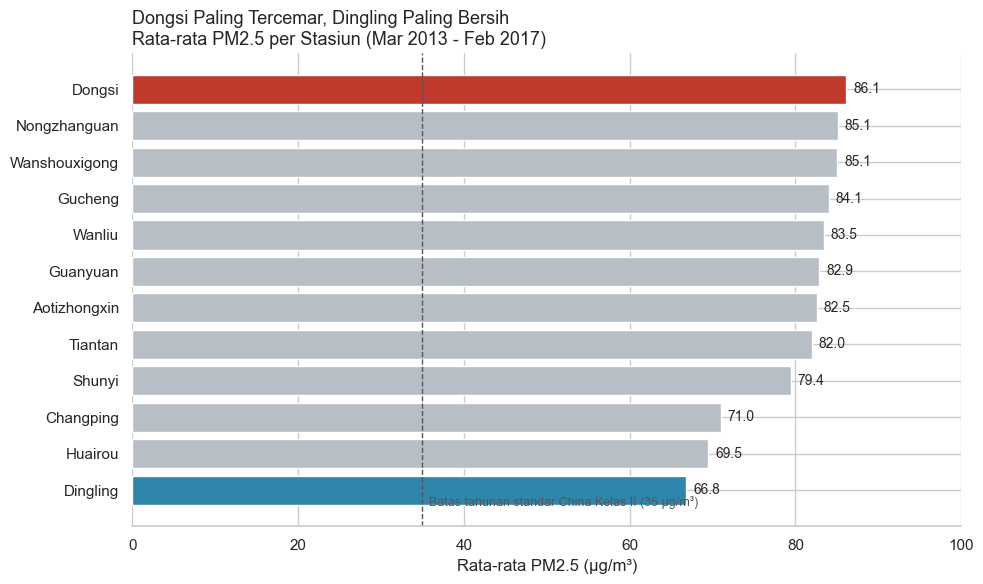

In [9]:
station_pm25 = df.groupby('station')['PM2.5'].mean().sort_values(ascending=False)
warna = ['#C0392B' if s == station_pm25.index[0] else '#2E86AB' if s == station_pm25.index[-1] else '#B8BEC6' for s in station_pm25.index]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(station_pm25.index, station_pm25.values, color=warna)
ax.invert_yaxis()
for i, v in enumerate(station_pm25.values):
    ax.text(v + 0.8, i, f'{v:.1f}', va='center', fontsize=10)
ax.axvline(35, color='#555555', linestyle='--', linewidth=1)
ax.text(35.8, len(station_pm25) - 0.55, 'Batas tahunan standar China Kelas II (35 µg/m³)', fontsize=9, color='#555555')
ax.set_xlim(0, 100)
ax.set_title('Dongsi Paling Tercemar, Dingling Paling Bersih\nRata-rata PM2.5 per Stasiun (Mar 2013 - Feb 2017)', fontsize=13, loc='left')
ax.set_xlabel('Rata-rata PM2.5 (µg/m³)')
ax.set_ylabel('')
sns.despine(left=True)
plt.tight_layout()
plt.show()

**Insight Pertanyaan 1:**
- Dongsi (86,1 µg/m³) adalah stasiun dengan PM2.5 tertinggi dan Dingling (66,8 µg/m³) yang terendah; selisihnya sekitar **29%**.
- Sembilan stasiun berada pada rentang sempit 79–86 µg/m³, sedangkan tiga stasiun terendah (Dingling, Huairou, Changping) berada di 67–71 µg/m³.
- Seluruh stasiun, termasuk yang terendah, hampir **2x lipat** di atas batas tahunan 35 µg/m³, sehingga masalah polusi bersifat merata, bukan hanya di satu lokasi.

### Pertanyaan 2:

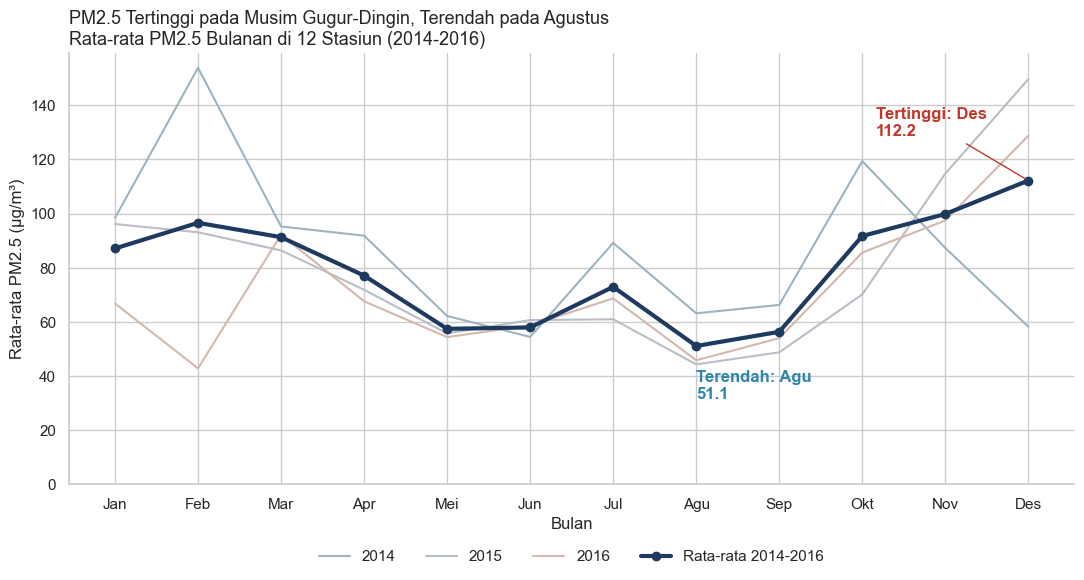

In [10]:
bulan_lbl = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']
pivot = df_full.groupby(['month', 'year'])['PM2.5'].mean().unstack()
rata = pivot.mean(axis=1)

fig, ax = plt.subplots(figsize=(11, 6))
for y, c in zip(pivot.columns, ['#9DB4C0', '#B8BEC6', '#D3B8AE']):
    ax.plot(range(1, 13), pivot[y], color=c, linewidth=1.5, label=str(y))
ax.plot(range(1, 13), rata, color='#1F3A5F', linewidth=3, marker='o', label='Rata-rata 2014-2016')
bmax, bmin = rata.idxmax(), rata.idxmin()
ax.annotate(f'Tertinggi: Des\n{rata[bmax]:.1f}', (bmax, rata[bmax]), textcoords='offset points', xytext=(-110, 32), color='#C0392B', fontweight='bold', arrowprops=dict(arrowstyle='-', color='#C0392B'))
ax.annotate(f'Terendah: Agu\n{rata[bmin]:.1f}', (bmin, rata[bmin]), textcoords='offset points', xytext=(0, -38), color='#2E86AB', fontweight='bold')
ax.set_xticks(range(1, 13)); ax.set_xticklabels(bulan_lbl)
ax.set_ylim(0, None)
ax.set_title('PM2.5 Tertinggi pada Musim Gugur-Dingin, Terendah pada Agustus\nRata-rata PM2.5 Bulanan di 12 Stasiun (2014-2016)', fontsize=13, loc='left')
ax.set_xlabel('Bulan'); ax.set_ylabel('Rata-rata PM2.5 (µg/m³)')
ax.legend(frameon=False, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.12))
sns.despine()
plt.tight_layout()
plt.show()

**Insight Pertanyaan 2:**
- Pola musiman jelas: rata-rata bulanan tertinggi pada **Desember (112,2)**, lalu Nov (99,8), Feb (95,9), Okt (91,7), dan Mar (91,3), terendah pada **Agustus (51,1)** (rasio ±2,2x).
- Garis per tahun memperlihatkan variasi antar tahun yang besar (misalnya Februari: 153,8 pada 2014 vs 42,8 pada 2016), jadi rata-rata tiga tahun menunjukkan pola umum, bukan nilai pasti tiap tahun.
- Tidak ada satu pun bulan yang rata-ratanya mendekati batas 35 µg/m³; bahkan bulan terbersih (Agustus) masih sekitar 1,5x lipat di atasnya.

## Analisis Lanjutan (Opsional)

### Analisis Lanjutan: Binning Kategori Kualitas Udara (Berbasis Ambang Batas PM2.5)

**Penjelasan dan tujuan teknik:** *Binning* (pengelompokan nilai kontinu ke dalam kategori) dipakai untuk mengubah nilai PM2.5 harian menjadi kategori kualitas udara yang lebih mudah dipahami pembuat kebijakan dan masyarakat. Kategori mengikuti titik batas PM2.5 rata-rata 24 jam pada indeks kualitas udara China (AQI): 0–35 sangat baik, 35–75 baik, 75–115 polusi ringan, 115–150 polusi sedang, 150–250 polusi berat, >250 polusi sangat berat. Tujuannya: (1) mengukur **seberapa sering** udara berada pada kategori tidak sehat (bukan sekadar rata-rata yang bisa tersamar oleh nilai ekstrem), dan (2) mendukung rekomendasi berbasis frekuensi hari berpolusi.

{'Sangat baik (0-35)': 29.5, 'Baik (35-75)': 30.1, 'Polusi ringan (75-115)': 18.2, 'Polusi sedang (115-150)': 9.5, 'Polusi berat (150-250)': 9.2, 'Polusi sangat berat (>250)': 3.4}
Hari dengan PM2.5 > 75 µg/m³: 40.3%
Persentase hari > 75 per bulan: {1: 46.7, 2: 43.0, 3: 51.1, 4: 42.3, 5: 30.3, 6: 36.6, 7: 40.9, 8: 25.2, 9: 32.8, 10: 42.7, 11: 47.0, 12: 45.8}


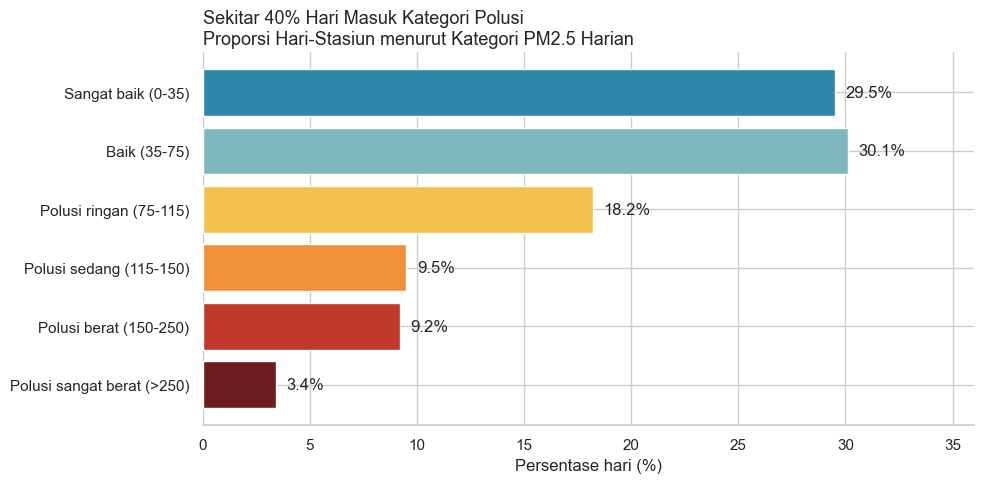

main_data.csv tersimpan: (17532, 13)


In [11]:
# Rata-rata harian per stasiun, lalu dikelompokkan dengan binning
daily = df.groupby(['station', 'date'])[['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'WSPM']].mean().reset_index()
daily['date'] = pd.to_datetime(daily['date'])
bins = [0, 35, 75, 115, 150, 250, 1000]
labels = ['Sangat baik (0-35)', 'Baik (35-75)', 'Polusi ringan (75-115)', 'Polusi sedang (115-150)', 'Polusi berat (150-250)', 'Polusi sangat berat (>250)']
daily['kategori'] = pd.cut(daily['PM2.5'], bins=bins, labels=labels)

kat = daily['kategori'].value_counts(normalize=True).reindex(labels).mul(100).round(1)
print(kat.to_dict())
print(f'Hari dengan PM2.5 > 75 µg/m³: {(daily["PM2.5"] > 75).mean()*100:.1f}%')
bulan_polusi = daily.assign(bulan=daily['date'].dt.month).groupby('bulan')['PM2.5'].apply(lambda x: (x > 75).mean() * 100).round(1)
print('Persentase hari > 75 per bulan:', bulan_polusi.to_dict())

fig, ax = plt.subplots(figsize=(10, 5))
warna_kat = ['#2E86AB', '#7FB7BE', '#F2C14E', '#F28F3B', '#C0392B', '#6B1D1D']
ax.barh(kat.index, kat.values, color=warna_kat)
ax.invert_yaxis()
for i, v in enumerate(kat.values):
    ax.text(v + 0.5, i, f'{v:.1f}%', va='center')
ax.set_xlim(0, 36)
ax.set_title('Sekitar 40% Hari Masuk Kategori Polusi\nProporsi Hari-Stasiun menurut Kategori PM2.5 Harian', fontsize=13, loc='left')
ax.set_xlabel('Persentase hari (%)'); ax.set_ylabel('')
sns.despine(left=True)
plt.tight_layout()
plt.show()

# Simpan data harian bersih untuk dashboard
import os
os.makedirs('dashboard', exist_ok=True)
main_data = daily.copy()
main_data['kategori'] = main_data['kategori'].astype(str)
main_data['year'] = main_data['date'].dt.year
main_data['month'] = main_data['date'].dt.month
main_data.assign(**{c: main_data[c].round(2) for c in ['PM2.5','PM10','SO2','NO2','CO','O3','TEMP','WSPM']}).to_csv('dashboard/main_data.csv', index=False)
print('main_data.csv tersimpan:', main_data.shape)

**Insight Analisis Lanjutan:**
- Hanya sekitar **59,6%** hari-stasiun berada pada kategori sangat baik atau baik (≤75 µg/m³), sedangkan sekitar **40,3%** hari masuk kategori polusi ringan hingga sangat berat (>75 µg/m³).
- Sekitar **12,6%** hari berada pada polusi berat atau sangat berat (>150 µg/m³), episode yang berisiko tinggi bagi kesehatan.
- Berdasarkan frekuensi hari berpolusi (>75 µg/m³), **Maret (51,1%)** adalah bulan yang paling sering berpolusi, sedangkan **Agustus (25,2%)** paling jarang. Ini melengkapi rata-rata bulanan: Desember memiliki rata-rata tertinggi, tetapi Maret memiliki frekuensi hari berpolusi tertinggi.

### Rangkuman Insight per Tahapan
- **Gathering Data:** 12 file stasiun digabung menjadi 420.768 baris x 18 kolom dengan jumlah data seimbang per stasiun.
- **Assessing Data:** ditemukan missing value (terbanyak di CO), 5,2% baris PM10 < PM2.5 (invalid), dan outlier PM2.5 tinggi yang merupakan kejadian polusi nyata; tidak ada duplikat.
- **Cleaning Data:** waktu dikonversi ke datetime, missing diisi interpolasi per stasiun, nilai PM10 tidak valid diperbaiki; hasil akhir tanpa missing value.
- **EDA:** Dongsi tertinggi dan Dingling terendah; Desember tertinggi dan Agustus terendah; PM2.5 berkorelasi kuat dengan CO dan NO2 serta menurun saat angin kencang.
- **Explanatory Analysis:** visualisasi memperlihatkan selisih antar stasiun ±29% dan pola musiman dengan rasio ±2,2x.
- **Analisis Lanjutan:** ±40% hari berada pada kategori polusi (>75 µg/m³).

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Stasiun dengan rata-rata PM2.5 tertinggi adalah **Dongsi (86,1 µg/m³)** dan terendah **Dingling (66,8 µg/m³)**, selisih sekitar **29%**. Perbedaannya moderat dan seluruh stasiun tetap hampir dua kali lipat di atas batas tahunan 35 µg/m³, sehingga pencemaran bersifat luas.
- **Conclusion pertanyaan 2:** Pada 2014–2016 rata-rata PM2.5 tertinggi pada **Desember (112,2 µg/m³)** dan terendah pada **Agustus (51,1 µg/m³)**, rasio sekitar **2,2x**. Periode **Oktober–Maret** adalah musim polusi dengan rata-rata di atas 87 µg/m³, dan Maret memiliki frekuensi hari berpolusi tertinggi (51,1% hari >75 µg/m³).

**Rekomendasi Action Item:**
- **Prioritaskan intervensi dan pemantauan intensif** di stasiun/wilayah dengan PM2.5 tertinggi (Dongsi, Nongzhanguan, Wanshouxigong, Gucheng; semuanya ≥84 µg/m³), misalnya pembatasan emisi kendaraan dan sumber lokal.
- **Jadwalkan pengetatan pengendalian emisi dan kampanye imbauan kesehatan (masker, pembatasan aktivitas luar ruang) pada Oktober–Maret**, dengan kewaspadaan puncak di Nov–Des.
- **Gunakan kondisi angin lemah (≤2 m/s) sebagai sinyal peringatan dini**, karena PM2.5 rata-rata pada kondisi ini 85–102 µg/m³ dibanding 29 µg/m³ saat angin >4 m/s.
- Untuk analisis berikutnya, tambahkan data sumber emisi (lalu lintas, pemanas) agar hubungan sebab-akibat dapat diuji, bukan sekadar korelasi.